# Персональные top-10 рекомендации: пять моделей с нуля
**Ситников Серафим Владимирович**

Задача: ранжировать музыкальные товары Amazon для пользователей с известной историей. Наблюдаемое взаимодействие — отзыв с оценкой 1–5; релевантность во всех экспериментах — будущий **первый отзыв с оценкой ≥ 4**. Отзыв не равен покупке или прослушиванию; отсутствие отзыва не означает отрицательное предпочтение.

До подбора фиксируем основную метрику **macro NDCG@10**: важен порядок в короткой выдаче. Дополнительные метрики — **macro Recall@10**, доля найденных релевантных товаров, и **Coverage@10**, доля каталога, появившаяся хотя бы в одной выдаче. Последняя описывает разнообразие каталога, но не точность.

## 1. Источник и воспроизведение
Используем **Amazon Reviews 2018 / Digital Music / 5-core**, подготовленный Jianmo Ni, Jiacheng Li и Julian McAuley. [Первоисточник](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/), [публикация EMNLP 2019](https://aclanthology.org/D19-1018/). На сайте указаны 169 781 отзыв в 5-core, 1 584 082 отзыва в полной категории и 465 392 записи метаданных. Используем всю 5-core выборку, без случайного или популярностного отбора. Уже само построение 5-core использует активность за весь период: это ограничение отбора данных, а не информация для моделей.

Файлы: [отзывы](https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Digital_Music_5.json.gz), [метаданные](https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/metaFiles2/meta_Digital_Music.json.gz). Код скачивает их по HTTPS и проверяет SHA-256 из `data_checksums.json`. Данные не хранятся в репозитории.

Поля отзывов: `reviewerID` — пользователь, `asin` — объект, `overall` — оценка, `unixReviewTime` — время UTC (точность до дня), `style["Format:"]` — формат товара. Названия, категории и brand из файла метаданных нужны для EDA/читаемых примеров. Тексты отзывов, helpfulness, verified purchase, цены, sales rank и связи also-bought в модели не входят.

Запуск из корня репозитория (Python 3.11, CPU; нужен интернет для первого скачивания):
```bash
python3.11 -m venv .venv
source .venv/bin/activate
pip install -r hw1/requirements.txt
# Полная фиксация окружения исходного запуска: hw1/requirements-lock.txt
cd hw1
python checks.py
python run_notebook.py
```
`run_notebook.py` исполняет этот ноутбук целиком и сохраняет outputs ячеек. Можно открыть его в Jupyter и выполнить Run All. `RECSYS_DATA` задаёт каталог кеша; по умолчанию `.cache/amazon` относительно hw1. Нужны несколько ГБ свободной RAM для плотной матрицы EASE; время зависит от BLAS/CPU. Все модели запускаются на CPU, seed=42, два вычислительных потока. Битовая идентичность между разными BLAS не гарантируется; методика и результаты воспроизводятся с обычной численной погрешностью.

In [1]:
import os, sys, json, platform, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from data_utils import download, load, split, TrainingData, SEED
from models import ItemKNN, IALS, EASE, FM, RatingRecencyALS
from evaluation import relevance, paired_bootstrap
from experiment import GRIDS, tune, final_evaluation
from checks import run_checks
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(2); torch.use_deterministic_algorithms(True)
thread_limits = threadpool_limits(limits=2)
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
print('Python',platform.python_version(),'NumPy',np.__version__,'pandas',pd.__version__,'torch',torch.__version__)
run_checks()
data_dir, hashes = download()
print('SHA-256:',json.dumps(hashes,indent=2))
raw, clean, metadata = load(data_dir)
print('Исходная 5-core:',len(raw),'очищенная:',len(clean),
      'пользователей:',clean.user.nunique(),'объектов:',clean.item.nunique())

Python 3.11.12 NumPy 2.4.6 pandas 3.1.1 torch 2.15.0
PASS: KNN, EASE, ALS normal equations, custom targets, FM pairs/gradient, ranking/masking
SHA-256: {
  "Digital_Music_5.json.gz": "703f60f74bf1967a75cbb3033532172eeb21139d4df04ec5fe44a7eb8d7fde58",
  "meta_Digital_Music.json.gz": "c044fdd1804a4ff619764f1db47efdc28585d186392e9daf7fd42e3b6bb41559"
}


Исходная 5-core: 169781 очищенная: 145292 пользователей: 16566 объектов: 11797


## 2. EDA и очистка
Проверяем обязательные поля и допустимый диапазон оценок. Повторы пары user–item схлопываем до **первого** события (stable sort по времени, user и item, затем исходный порядок файла). Это соответствует рекомендации ещё не известных товаров и не позволяет более поздней оценке заменить раннюю. Новое удаление малоактивных пользователей не выполняем: иначе пришлось бы выбирать их по будущей активности. Пропущенный формат заменяем на `unknown`.

,missing
user,0
item,0
rating,0
timestamp,0
format,0
format_unknown,11792


,raw_5core,clean
interactions,169781,145292
users,16566,16566
items,11797,11797


Повторных пар: 24489
Оценки вне 1..5: 0
Повторных точных строк: 23839
Разреженность: 0.9992565488020305
Доля rating>=4: 0.9352820526938854
Период UTC: 1998-07-09 00:00:00 — 2018-09-26 00:00:00


,user_activity,item_popularity
count,16566.000000,11797.000000
mean,8.770494,12.316013
std,10.212211,15.689818
min,1.000000,1.000000
25%,5.000000,6.000000
50%,6.000000,8.000000
75%,9.000000,13.000000
max,557.000000,572.000000


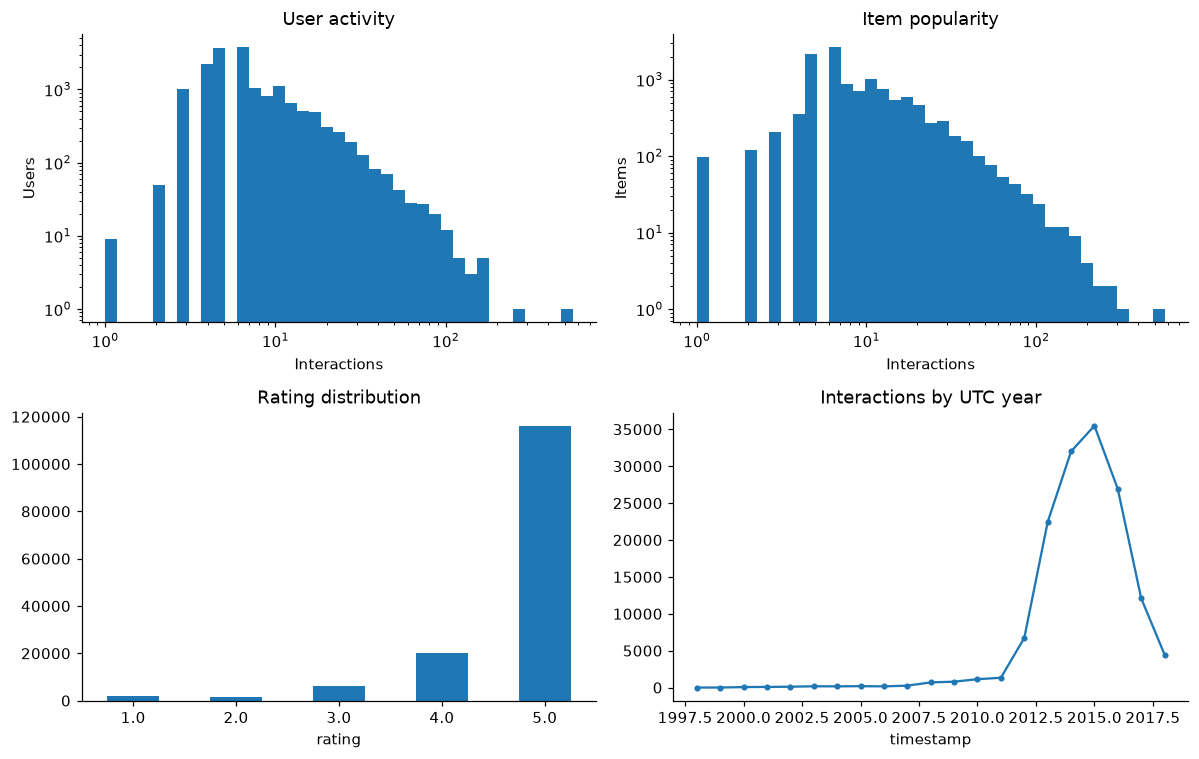

In [2]:
missing = raw.isna().sum().rename('missing').to_frame()
missing.loc['format_unknown','missing'] = int(raw['format'].eq('unknown').sum())
display(missing)
summary = pd.DataFrame({
 'raw_5core':[len(raw),raw.user.nunique(),raw.item.nunique()],
 'clean':[len(clean),clean.user.nunique(),clean.item.nunique()]},
 index=['interactions','users','items'])
display(summary)
print('Повторных пар:',len(raw)-len(clean))
print('Оценки вне 1..5:',int((~raw.rating.between(1,5)).sum()))
print('Повторных точных строк:',int(raw.duplicated().sum()))
print('Разреженность:',1-len(clean)/(clean.user.nunique()*clean.item.nunique()))
print('Доля rating>=4:',clean.rating.ge(4).mean())
print('Период UTC:',pd.to_datetime(clean.timestamp.min(),unit='s'),
      '—',pd.to_datetime(clean.timestamp.max(),unit='s'))
activity=clean.groupby('user').size(); popularity=clean.groupby('item').size()
display(pd.DataFrame({'user_activity':activity.describe(),'item_popularity':popularity.describe()}))
fig,ax=plt.subplots(2,2,figsize=(11,7))
ax[0,0].hist(activity,bins=np.geomspace(1,activity.max()+1,40));ax[0,0].set(xscale='log',yscale='log',title='User activity',xlabel='Interactions',ylabel='Users')
ax[0,1].hist(popularity,bins=np.geomspace(1,popularity.max()+1,40));ax[0,1].set(xscale='log',yscale='log',title='Item popularity',xlabel='Interactions',ylabel='Items')
clean.rating.value_counts().sort_index().plot.bar(ax=ax[1,0],rot=0,title='Rating distribution')
yearly=pd.to_datetime(clean.timestamp,unit='s').dt.year.value_counts().sort_index()
yearly.plot(ax=ax[1,1],title='Interactions by UTC year',marker='.')
fig.tight_layout();plt.show()

Покрытие метаданными: 0.015681953038908198


,missing
title,0
category,0
brand,0


,catalog_entries
category,


,interactions
format,
MP3 Music,125150
Audio CD,10210
unknown,9576
Vinyl,307
DVD,22
Audio Cassette,8
Blu-ray Audio,7
Blu-ray,6
Amazon Video,3


,title,brand
3426958910,Slayer - Greatest Hits 2 CD Set,Slayer
5557505946,Something to Say,Matthew West
5557706259,The Altar and the Door,Casting Crowns
5559166928,He Touched Me: The Gospel Music of Elvis Presley,Elvis Presley
7799420340,Essential,Michael Jackson


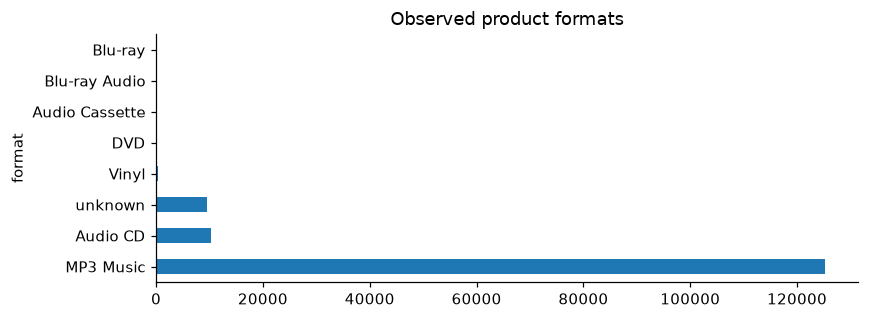

In [3]:
catalog=pd.DataFrame.from_dict(metadata,orient='index')
print('Покрытие метаданными:',len(catalog)/clean.item.nunique())
display(catalog.isna().sum().rename('missing').to_frame())
# Категории — списки из snapshot каталога, только описательная статистика.
categories=catalog['category'].explode().dropna().astype(str)
display(categories.value_counts().head(15).rename('catalog_entries').to_frame())
display(clean['format'].value_counts().head(12).rename('interactions').to_frame())
display(catalog[['title','brand']].head(5))
fig,ax=plt.subplots(figsize=(8,3))
clean['format'].value_counts().head(8).plot.barh(ax=ax,title='Observed product formats');fig.tight_layout();plt.show()

## 3. Единый временной протокол
Глобальные границы — 80-й и 90-й процентили timestamp очищенных данных. Все события на одной границе-дате попадают целиком в следующий интервал: train $t<T_1$, validation $T_1\le t<T_2$, test $t\ge T_2$. Времена отзывов имеют дневную точность; будущие события не подмешиваются в train. Это два статических snapshot, без обновления модели внутри окна.

Каталог и отображения ID фиксируются **только по train**. Кандидаты каждого пользователя — все train-объекты минус все уже оценённые им объекты (включая оценки 1–3). Никакого сэмплирования кандидатов при оценке. Validation использует историю train. После выбора настроек модели переобучаются на train+validation, test исключает всю эту историю. Каталог остаётся train-каталогом, поэтому предмет сравнения одинаков.

Холодных пользователей и объекты исключаем из warm-start эксперимента; таблица ниже показывает потери. Для каждого окна оцениваем всех warm-пользователей с хотя бы одним релевантным объектом среди кандидатов. Их список идентичен для всех моделей внутри окна. Validation и test могут содержать разные списки пользователей. Пользователи без релевантных объектов не входят в macro-метрики (Recall для них не определён). Правило одинаково для всех моделей.

$$\operatorname{Recall@10}(u)=\frac{|L_u^{10}\cap R_u|}{|R_u|},\quad
\operatorname{NDCG@10}(u)=\frac{\sum_{j=1}^{10}\mathbf1[L_{uj}\in R_u]/\log_2(j+1)}{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)}.$$
Итог — среднее по пользователям. При равенстве score приоритет у меньшего индекса объекта (индексы соответствуют лексикографически отсортированным ASIN).

In [4]:
train, validation, test, shape, (t1,t2), audit = split(clean)
display(audit)
print('Границы UTC:',pd.to_datetime([t1,t2],unit='s').tolist())
print('Размер матрицы train:',shape)
assert train.timestamp.max()<validation.timestamp.min()<=validation.timestamp.max()<test.timestamp.min()
assert not set(zip(train.u,train.i)) & set(zip(validation.u,validation.i))
assert not set(zip(train.u,train.i)) & set(zip(test.u,test.i))
assert not set(zip(validation.u,validation.i)) & set(zip(test.u,test.i))
train_data=TrainingData(train,shape,t1)
final_data=TrainingData(pd.concat([train,validation],ignore_index=True),shape,t2)
for name,frame,data in [('validation',validation,train_data),('test',test,final_data)]:
    rel=relevance(frame,data.seen)
    print(name,': пользователей',len(rel),'; релевантных пар',sum(map(len,rel.values())))
    assert all(data.seen[u,list(items)].nnz==0 for u,items in rel.items())
print('Протокол: PASS')

,split,raw_events,warm_events,cold_user_events,cold_item_events
0,train,116209,116209,0,0
1,validation,14518,8464,5212,1024
2,test,14565,7077,6919,820


Границы UTC: [Timestamp('2016-06-16 00:00:00'), Timestamp('2017-02-01 00:00:00')]
Размер матрицы train: (15273, 11611)


validation : пользователей 2756 ; релевантных пар 8120
test : пользователей 2233 ; релевантных пар 6716


Протокол: PASS


## 4. Реализации и постановки
Все пять реализаций находятся в отдельных файлах `models/`; используются матричные операции NumPy/SciPy и autograd PyTorch, без библиотек рекомендательных моделей и готовых обучаемых алгоритмов. Общий интерфейс `fit(data)` и `score(users)`; top-10, маскирование и метрики реализованы в `evaluation.py`. Проверки в `checks.py` независимо сверяют KNN с плотной формулой, EASE с прямым обращением, нормальные уравнения ALS, FM с явной суммой пар и конечной разностью градиента, а также метрики и маску истории.

### ItemKNN
$X_{ui}=1[r_{ui}\ge4]$ для наблюдавшихся отзывов, иначе 0. Сходство $s_{ij}=(X^TX)_{ij}/(\|X_i\|\|X_j\|+\lambda_s)$, $s_{ii}=0$. Оставляем $k$ соседей **на каждый целевой объект**; $\hat y_{uj}=\sum_iX_{ui}s_{ij}$. Shrinkage уменьшает влияние сходства, рассчитанного по редким объектам.

### Базовый iALS
$\Omega$ — все наблюдаемые пары, включая низкие оценки. $p_{ui}=1[(u,i)\in\Omega\land r_{ui}\ge4]$, $c_{ui}=1+\alpha\mathbf1[(u,i)\in\Omega]$. Низкая оценка — наблюдаемый нулевой таргет с повышенной уверенностью; отсутствие отзыва — ноль с единичной уверенностью.
$$\min_{A,B}\sum_{ui}c_{ui}(p_{ui}-a_u^Tb_i)^2+\lambda(\|A\|_F^2+\|B\|_F^2).$$
Чередуем точные решения нормальных уравнений, например
$$a_u=(B^TB+\alpha\sum_{i\in\Omega_u}b_ib_i^T+\lambda I)^{-1}(1+\alpha)\sum_{i\in\Omega_u}p_{ui}b_i.$$
Обращение здесь — математическое обозначение; в коде используется `solve`. Скор — скалярное произведение.

### EASE
$$\min_W\|X-XW\|_F^2+\lambda\|W\|_F^2,\quad\operatorname{diag}(W)=0.$$
$P=(X^TX+\lambda I)^{-1}$, $W_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$, $W_{ii}=0$; score $XW$. Вычисляем через разложение Холецкого. Нет запрета на отрицательные веса; они позволяют учитывать отрицательные условные связи.

### FM с метапризнаками
$$f(x)=w_0+\sum_jw_jx_j+\tfrac12\sum_f[(\sum_jv_{jf}x_j)^2-\sum_jv_{jf}^2x_j^2].$$
Признаки кодируются раздельными one-hot полями: user ID, item ID; логарифмические бакеты активности пользователя и популярности объекта; округлённые средние оценки пользователя и объекта; бакет времени с последнего отзыва об объекте на cutoff; формат товара из **первого наблюдавшегося обучающего отзыва**. Все агрегаты заново вычисляются по соответствующей обучающей истории. Оценка целевой пары при прогнозе никогда не является входным признаком. Исторические оценки собственных train-пар входят в агрегаты при обучении; validation/test не входят. Это допустимый train-only fit, но может усиливать переобучение на редких объектах.

Мотивация: активность и средние оценки описывают разную склонность писать положительные отзывы; популярность и давность — доступность/актуальность; формат может отражать различие вкусов к цифровым записям, CD и винилу. Поле формата — атрибут уже наблюдаемого товара; у него возможны варианты/ошибки, и мы не предполагаем наличие актуального snapshot всей карточки товара. Категории и названия из недатированного файла **не являются признаками модели**. Такой выбор использует только известную к cutoff историю и её метаданные.

Обучаем бинарную cross-entropy через autograd и Adam с L2 weight decay. Все наблюдаемые оценки ≥4 — положительные, 1–3 — отрицательные; на каждую положительную пару добавляем 2 равномерно выбранных ненаблюдаемых отрицательных объекта. Отрицательные пересэмплируются каждую эпоху, все известные пары отклоняются. Будущую историю для отклонения не используем. Весь каталог ранжируется по логиту; отрицательный sampling нужен только для обучения. ID-only абляция использует те же выбранные параметры и seed и отключает шесть полей метапризнаков.

### CustomALS: собственный таргет рейтинга и давности
Для наблюдаемой пары предлагаем
$$q_{ui}=\frac{r_{ui}-3}{2}\left(\tfrac12+\tfrac12\,2^{-(T-t_{ui})/(86400h)}\right),\quad (u,i)\in\Omega;\qquad q_{ui}=0\text{ иначе}.$$
Здесь $T$ — cutoff обучения, $h$ — период полураспада в днях. Оценки 1–2 дают отрицательный сигнал, 3 — нейтральный, 4–5 — положительный разной силы. Старые предпочтения ослабляются, но сохраняют хотя бы половину амплитуды. Это гипотеза об изменении вкуса, которую проверяем экспериментально, а не утверждение о данных.

Оптимизируем **ту же ALS функцию**, заменив $p$ на $q$. **Confidence, инициализация, размерность, регуляризация и число итераций совпадают с выбранным базовым iALS**. Меняется правая часть нормальных уравнений, не только веса ошибки. Полураспад выбирается по validation. На test релевантность остаётся rating≥4 для всех моделей; временные веса в метрике отсутствуют.

### Пространство поиска, зафиксированное до test
Выбираем максимум validation NDCG@10; при точном равенстве — первую конфигурацию в списке. Не подбираем число эпох по test. ItemKNN — 2 пары `(neighbors, shrink)`; iALS — сетка 2 размерности × 2 регуляризации; EASE — 2 регуляризации; FM — 2 размерности × 2 L2. Для CustomALS условное пространство — выбранные на validation параметры iALS × два полураспада. Такая схема обеспечивает контролируемую проверку изменения таргета и ограниченный бюджет; оптимальность за пределами этой сетки не заявляем.

Численные значения сетки: ItemKNN `(neighbors, shrink)` = `(30,10)` или `(100,30)`; iALS `factors ∈ {16,32}`, `reg ∈ {1,10}`, `alpha=20`, `iterations=8`; EASE `reg ∈ {100,500}`; FM `factors ∈ {16,32}`, `reg ∈ {1e-5,1e-4}`, `lr=0.01`, `epochs=8`, `negatives=2`; CustomALS `h ∈ {365,1460}` дней при остальных параметрах выбранного iALS. Везде seed=42.

In [5]:
display(pd.DataFrame([{'model':name,'configurations':len(grid),'space':json.dumps(grid,ensure_ascii=False)}
                      for name,grid in GRIDS.items()]))
print('CustomALS: выбранные iALS-параметры + half_life ∈ {365,1460} дней')
validation_results, selected = tune(train,validation,shape,t1)
display(validation_results.sort_values(['model','NDCG@10'],ascending=[True,False]))
print('Замороженные настройки:');print(json.dumps(selected,indent=2,ensure_ascii=False))

,model,configurations,space
0,ItemKNN,2,"[{""neighbors"": 30, ""shrink"": 10.0}, {""neighbor..."
1,iALS,4,"[{""factors"": 16, ""reg"": 1.0, ""alpha"": 20.0, ""i..."
2,EASE,2,"[{""reg"": 100.0}, {""reg"": 500.0}]"
3,FM,4,"[{""factors"": 16, ""lr"": 0.01, ""reg"": 1e-05, ""ep..."


CustomALS: выбранные iALS-параметры + half_life ∈ {365,1460} дней


ItemKNN {'neighbors': 30, 'shrink': 10.0} {'NDCG@10': 0.015317531414123235, 'Recall@10': 0.024077142395953495, 'Coverage@10': 0.6788390319524589, 'users': 2756} fit seconds 0.11


ItemKNN {'neighbors': 100, 'shrink': 30.0} {'NDCG@10': 0.015316412548588294, 'Recall@10': 0.025543403724814073, 'Coverage@10': 0.6068383429506502, 'users': 2756} fit seconds 0.09


iALS {'factors': 16, 'reg': 1.0, 'alpha': 20.0, 'iterations': 8, 'seed': 42} {'NDCG@10': 0.013178896245429082, 'Recall@10': 0.0189827722602082, 'Coverage@10': 0.04788562569976746, 'users': 2756} fit seconds 2.46


iALS {'factors': 16, 'reg': 10.0, 'alpha': 20.0, 'iterations': 8, 'seed': 42} {'NDCG@10': 0.013184823927295084, 'Recall@10': 0.01900545005411241, 'Coverage@10': 0.046679872534665406, 'users': 2756} fit seconds 2.48


... (8 outputs left out)

CustomALS {'factors': 32, 'reg': 1.0, 'alpha': 20.0, 'iterations': 8, 'seed': 42, 'half_life': 365.0} {'NDCG@10': 0.017387479965251345, 'Recall@10': 0.026404081072184792, 'Coverage@10': 0.0918956162259926, 'users': 2756} fit seconds 3.67


CustomALS {'factors': 32, 'reg': 1.0, 'alpha': 20.0, 'iterations': 8, 'seed': 42, 'half_life': 1460.0} {'NDCG@10': 0.01561176099443423, 'Recall@10': 0.023348204017499066, 'Coverage@10': 0.08974248557402463, 'users': 2756} fit seconds 3.69


,model,params,fit_seconds,NDCG@10,Recall@10,Coverage@10,users
12,CustomALS,"{""alpha"": 20.0, ""factors"": 32, ""half_life"": 36...",3.665431,0.017387,0.026404,0.091896,2756
13,CustomALS,"{""alpha"": 20.0, ""factors"": 32, ""half_life"": 14...",3.688424,0.015612,0.023348,0.089742,2756
6,EASE,"{""reg"": 100.0}",27.473722,0.015826,0.024962,0.485402,2756
7,EASE,"{""reg"": 500.0}",21.039133,0.015201,0.024435,0.461717,2756
10,FM,"{""epochs"": 8, ""factors"": 32, ""lr"": 0.01, ""meta...",3.745646,0.004629,0.008403,0.052881,2756
8,FM,"{""epochs"": 8, ""factors"": 16, ""lr"": 0.01, ""meta...",3.077045,0.003927,0.006935,0.048144,2756
11,FM,"{""epochs"": 8, ""factors"": 32, ""lr"": 0.01, ""meta...",3.712609,0.003676,0.005922,0.004220,2756
9,FM,"{""epochs"": 8, ""factors"": 16, ""lr"": 0.01, ""meta...",2.856826,0.003590,0.005967,0.004220,2756
0,ItemKNN,"{""neighbors"": 30, ""shrink"": 10.0}",0.106896,0.015318,0.024077,0.678839,2756
1,ItemKNN,"{""neighbors"": 100, ""shrink"": 30.0}",0.089716,0.015316,0.025543,0.606838,2756


Замороженные настройки:
{
  "ItemKNN": {
    "neighbors": 30,
    "shrink": 10.0
  },
  "iALS": {
    "factors": 32,
    "reg": 1.0,
    "alpha": 20.0,
    "iterations": 8,
    "seed": 42
  },
  "EASE": {
    "reg": 100.0
  },
  "FM": {
    "factors": 32,
    "lr": 0.01,
    "reg": 1e-05,
    "epochs": 8,
    "negatives": 2,
    "metadata": true,
    "seed": 42
  },
  "CustomALS": {
    "factors": 32,
    "reg": 1.0,
    "alpha": 20.0,
    "iterations": 8,
    "seed": 42,
    "half_life": 365.0
  }
}


## 5. Финальная оценка на test
Настройки уже выбраны. Теперь один финальный проход на test после переобучения на train+validation. ID-only FM — заранее объявленная абляция с параметрами полной FM, её результаты не используются для повторного выбора. Интервалы — paired bootstrap по пользователям, 2 000 повторов, seed=42, 95%; они условны на этом временном разбиении и не отражают неопределённость обучения по разным seed.

TEST ItemKNN {'NDCG@10': 0.014929371856962937, 'Recall@10': 0.02442206802709395, 'Coverage@10': 0.6203600034450091, 'users': 2233}


TEST iALS {'NDCG@10': 0.01610460422522825, 'Recall@10': 0.025334380600536617, 'Coverage@10': 0.08827835673068642, 'users': 2233}


TEST EASE {'NDCG@10': 0.019412621085419343, 'Recall@10': 0.0292918492587429, 'Coverage@10': 0.41684609422099733, 'users': 2233}


TEST FM {'NDCG@10': 0.007919571484435187, 'Recall@10': 0.011371846857632746, 'Coverage@10': 0.04521574369132719, 'users': 2233}


TEST CustomALS {'NDCG@10': 0.017874525321113194, 'Recall@10': 0.027667685035210613, 'Coverage@10': 0.08776160537421411, 'users': 2233}


TEST FM_ID_only {'NDCG@10': 0.012586210013227234, 'Recall@10': 0.020315506299293167, 'Coverage@10': 0.020239428128498837, 'users': 2233}


,model,NDCG@10,Recall@10,Coverage@10,fit_seconds,users,params
0,EASE,0.019413,0.029292,0.416846,21.145920,2233,"{""reg"": 100.0}"
1,CustomALS,0.017875,0.027668,0.087762,3.677349,2233,"{""alpha"": 20.0, ""factors"": 32, ""half_life"": 36..."
2,iALS,0.016105,0.025334,0.088278,3.881431,2233,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 8..."
3,ItemKNN,0.014929,0.024422,0.620360,0.114890,2233,"{""neighbors"": 30, ""shrink"": 10.0}"
4,FM_ID_only,0.012586,0.020316,0.020239,2.376767,2233,"{""epochs"": 8, ""factors"": 32, ""lr"": 0.01, ""meta..."
5,FM,0.007920,0.011372,0.045216,4.095468,2233,"{""epochs"": 8, ""factors"": 32, ""lr"": 0.01, ""meta..."


,delta,lower,upper,users
CustomALS minus iALS,0.001770,-0.000565,0.004131,2233.0
FM minus FM_ID_only,-0.004667,-0.007043,-0.002000,2233.0


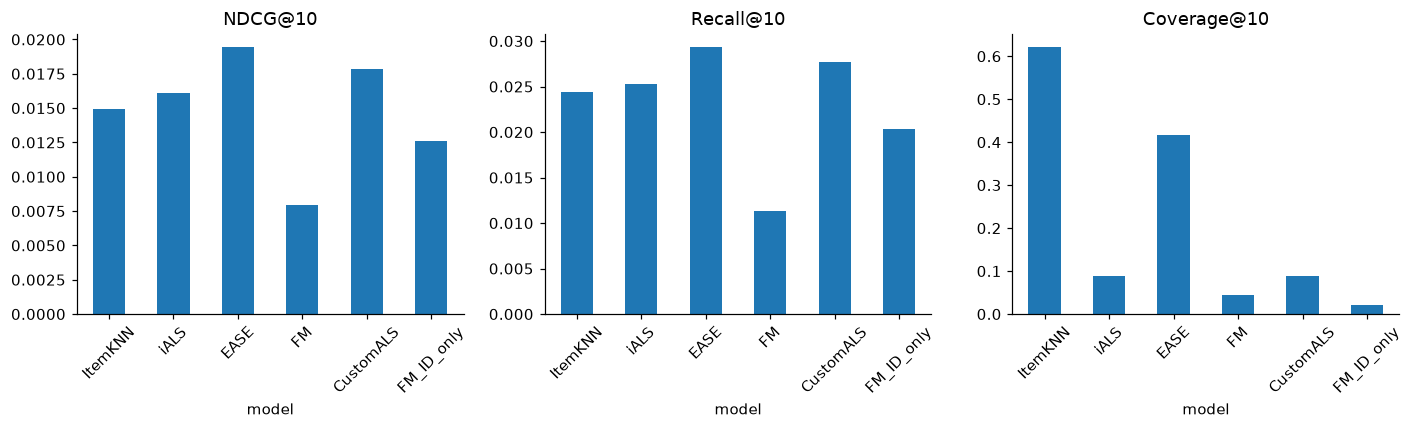

In [6]:
test_results, intervals = final_evaluation(train,validation,test,shape,t2,selected)
comparison=test_results[['model','NDCG@10','Recall@10','Coverage@10','fit_seconds','users','params']]
display(comparison.sort_values('NDCG@10',ascending=False).reset_index(drop=True))
display(pd.DataFrame(intervals).T)
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,metric in zip(axes,['NDCG@10','Recall@10','Coverage@10']):
    test_results.set_index('model')[metric].plot.bar(ax=ax,title=metric,rot=45)
fig.tight_layout();plt.show()

In [7]:
# Одинаковые пользователи во всех методах; названия добавляются только для чтения.
examples=pd.read_csv('results/recommendations.csv')
item_names=train[['i','item']].drop_duplicates('i').set_index('i')['item']
examples['title']=examples.i.map(lambda i:metadata.get(item_names[i],{}).get('title','[missing]'))
display(examples[examples.u==examples.u.min()][['model','rank','i','title']])
# Храним только агрегированные результаты, кодированные ID и примеры, без исходных отзывов.
print('Сохранены: validation.csv, selected.json, test.csv, per_user_*.csv, paired_intervals.json, recommendations.csv')

,model,rank,i,title
0,ItemKNN,1,4302,[missing]
1,ItemKNN,2,10448,[missing]
2,ItemKNN,3,3852,[missing]
3,ItemKNN,4,12,Slim Shady
4,ItemKNN,5,11184,[missing]
5,ItemKNN,6,11456,[missing]
6,ItemKNN,7,10679,[missing]
7,ItemKNN,8,11160,[missing]
8,ItemKNN,9,3014,[missing]
9,ItemKNN,10,5888,[missing]


Сохранены: validation.csv, selected.json, test.csv, per_user_*.csv, paired_intervals.json, recommendations.csv


## 6. Выводы по полученным результатам
Следующая ячейка формирует выводы из фактически вычисленных метрик и интервалов, чтобы они оставались согласованными при повторном запуске.

In [8]:
table=test_results.set_index('model')
main=table.drop(index='FM_ID_only')
best_ndcg=main['NDCG@10'].idxmax();best_recall=main['Recall@10'].idxmax()
lines=[f"Среди пяти основных моделей на этом test максимальный NDCG@10 у **{best_ndcg}** ({main.loc[best_ndcg,'NDCG@10']:.5f}), максимальный Recall@10 у **{best_recall}** ({main.loc[best_recall,'Recall@10']:.5f}). Это описание финального сравнения, а не новый этап подбора."]
for label in ['CustomALS minus iALS','FM minus FM_ID_only']:
    d=intervals[label]
    significance='интервал включает ноль — убедительного направления эффекта здесь нет' if d['lower']<=0<=d['upper'] else ('эффект положителен в этом разбиении' if d['lower']>0 else 'эффект отрицателен в этом разбиении')
    lines.append(f"**{label}:** ΔNDCG@10 = {d['delta']:+.5f}, paired 95% CI [{d['lower']:+.5f}, {d['upper']:+.5f}]; {significance}.")
lines.append('Выбранные настройки: '+ '; '.join(f"**{k}**: `{json.dumps(v,sort_keys=True)}`" for k,v in selected.items())+'.')
lines.append('Покрытие каталога и время обучения приведены рядом с точностью: высокое покрытие само по себе не означает хорошее ранжирование. ID-only абляция измеряет совокупный вклад выбранных метапризнаков при фиксированных параметрах; она не отделяет эффект каждого поля и не сравнивает независимо оптимизированные FM. CustomALS меняет одновременно рейтинг и давность, поэтому сравнение не позволяет отдельно приписать эффект затуханию.')
display(Markdown('\n\n'.join(lines)))

Среди пяти основных моделей на этом test максимальный NDCG@10 у **EASE** (0.01941), максимальный Recall@10 у **EASE** (0.02929). Это описание финального сравнения, а не новый этап подбора.

**CustomALS minus iALS:** ΔNDCG@10 = +0.00177, paired 95% CI [-0.00057, +0.00413]; интервал включает ноль — убедительного направления эффекта здесь нет.

**FM minus FM_ID_only:** ΔNDCG@10 = -0.00467, paired 95% CI [-0.00704, -0.00200]; эффект отрицателен в этом разбиении.

Выбранные настройки: **CustomALS**: `{"alpha": 20.0, "factors": 32, "half_life": 365.0, "iterations": 8, "reg": 1.0, "seed": 42}`; **EASE**: `{"reg": 100.0}`; **FM**: `{"epochs": 8, "factors": 32, "lr": 0.01, "metadata": true, "negatives": 2, "reg": 1e-05, "seed": 42}`; **ItemKNN**: `{"neighbors": 30, "shrink": 10.0}`; **iALS**: `{"alpha": 20.0, "factors": 32, "iterations": 8, "reg": 1.0, "seed": 42}`.

Покрытие каталога и время обучения приведены рядом с точностью: высокое покрытие само по себе не означает хорошее ранжирование. ID-only абляция измеряет совокупный вклад выбранных метапризнаков при фиксированных параметрах; она не отделяет эффект каждого поля и не сравнивает независимо оптимизированные FM. CustomALS меняет одновременно рейтинг и давность, поэтому сравнение не позволяет отдельно приписать эффект затуханию.

### Ограничения и интерпретация
- Отзывы — смещённый сигнал: пользователи выбирают, о чём писать. Релевантные товары без отзывов считаются ненаблюдаемыми. Полный каталог оценки сложнее sampled-negative оценки; малые абсолютные метрики ожидаемы и не доказывают бесполезность персонализации.
- Warm-start отбрасывает существенную долю будущих событий; потери явно показаны в таблице. Результаты нельзя переносить на новых пользователей/товары без отдельной модели cold-start.
- 5-core сформирован авторами по полному периоду. Повторные/связанные музыкальные издания могут оставаться разными ASIN; не считаем их одним объектом.
- Метаданные каталога — недатированный snapshot. Они используются лишь для EDA и подписей. Даже формат из первого отзыва может отражать вариант товара, а не постоянный атрибут всего ASIN. Исторические агрегаты осторожны по времени, но не являются богатыми семантическими признаками жанра или исполнителя.
- Одна глобальная временная разбивка, один seed, небольшое пространство поиска, фиксированное число эпох. Bootstrap оценивает только разброс по пользователям этого test. Нельзя делать общий вывод о превосходстве семейства методов.
- Внутри validation/test окна модель не обновляется. Это честная оценка статического snapshot, но не симуляция непрерывного сервиса. В продуктивной системе понадобятся rolling evaluation, cold-start стратегия, проверка вариативности seed и бизнес-метрики.

### Ссылки на формулы методов
[Implicit ALS: Hu, Koren, Volinsky, 2008](https://doi.org/10.1109/ICDM.2008.22); [EASE: Steck, 2019](https://arxiv.org/abs/1905.03375); [FM: Rendle, 2010](https://doi.org/10.1109/ICDM.2010.127). CustomALS — сформулированная здесь экспериментальная эвристика, без заявления о научной новизне.